# RAG Assignment: Dense Retrieval vs. Dense + Cross-Encoder Re-Ranking

**Plan of this notebook**

| Step | What happens |
|---|---|
| 0 | Configuration (document, models, LLM backend) |
| 1 | Read the PDF and build sentence-aware, page-tracked chunks |
| 2 | Embed chunks once with a bi-encoder |
| 3 | Define the two pipelines as small functions |
| 4 | Shared prompt + LLM wrapper (identNIST SP 800-63A-4 RAG: Baseline vs. Cross-Encoder Re-Ranking

This notebook compares two retrieval workflows over chunks extracted from the official NIST SP 800-63A-4: Digital Identity Guidelines — Identity Proofing and Enrollment PDF.

Baseline retrieval: Use a bi-encoder to retrieve the Top 10 relevant chunks, then send the top 3 to the answer generator.

Advanced retrieval: Re-rank those same 10 candidates using a cross-encoder, then send the re-ranked top 3 to the answer generator.

The notebook records the source PDF checksum, retrieval rank shifts, paired answers, and latency measurements. These outputs provide experimental evidence for comparing baseline dense retrieval with cross-encoder re-ranking.

Environment

Run this notebook in the Kaggle environment with the NIST SP 800-63A-4 PDF attached as an input dataset. Configure PDF_PATH to point to the PDF's actual location under /kaggle/input/.

Install the required dependencies if they are not already available. Select a supported answer-generation backend and configure its API key if required. Run the notebook cells in order to generate the retrieval results, answers, and evaluation outputs.

Important: Chunk counts, rank shifts, answer comparisons, and latency values must come from your actual notebook run; they should not be assumed in advance.ical for both pipelines) |
| 5 | Stress-test queries (keyword trap, exception, negation, buried chunk) |
| 6 | Automatic rank-shift table and failure detection |
| 7 | Answer 1 vs. Answer 2 side by side |
| 8 | Latency profiling + scaling experiment |
| 9 | Export results for the report |

> Everything printed here is real output from *your* run. Nothing is pre-filled.

**Document configured for this version:** NIST SP 800-63A-4, *Identity Proofing and Enrollment*.
Place `NIST.SP.800-63a-4.pdf` in the same folder as this notebook. The test questions and evidence patterns have been adapted to this publication. Run all cells from top to bottom; retrieval ranks, generated answers, timings, and CSV exports are produced by your run.

In [6]:
from pathlib import Path

pdfs = list(Path("/kaggle/input").rglob("*.pdf"))

for pdf in pdfs:
    print(pdf)

/kaggle/input/datasets/rakeshcr7/nsit-pdf/NIST.SP.800-63a-4.pdf


## 0. Configuration

In [7]:
%pip install -q pypdf sentence-transformers torch numpy pandas matplotlib google-genai openai requests

import os, re, time, json, statistics
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- EDIT THESE ----------
PDF_PATH = pdfs[0]  # keep this PDF beside the notebook
BI_ENCODER      = "BAAI/bge-small-en-v1.5"      # dense retriever (bi-encoder)
CROSS_ENCODER   = "cross-encoder/ms-marco-MiniLM-L-6-v2"
QUERY_PREFIX    = "Represent this sentence for searching relevant passages: "  # bge-specific; use "" for other models
LLM_BACKEND     = os.getenv("LLM_BACKEND", "gemini")   # gemini | openai | ollama
LLM_MODEL       = os.getenv("LLM_MODEL", "gemini-2.0-flash")  # change to any model your key supports
TARGET_WORDS    = 160    # soft size of a chunk
OVERLAP_SENTS   = 2      # sentences repeated between neighbouring chunks
TOP_K, TOP_N    = 10, 3  # retrieve 10, feed 3 to the LLM
# --------------------------------

assert PDF_PATH.exists(), f"Place NIST.SP.800-63a-4.pdf beside this notebook. Expected: {PDF_PATH.resolve()}"

Note: you may need to restart the kernel to use updated packages.


## 1. Chunking

Instead of cutting at a fixed word count, chunks are built by packing **whole sentences** until about `TARGET_WORDS` is reached, then the next chunk starts `OVERLAP_SENTS` sentences back. This keeps clauses such as *"except when ..."* attached to the rule they modify. Page numbers are tracked so any chunk can be traced to the source.

In [8]:
from pypdf import PdfReader

@dataclass
class Chunk:
    cid: int
    page: int
    text: str

def clean(t: str) -> str:
    t = re.sub(r"-\n(?=[a-z])", "", t)          # re-join hyphenated line breaks
    t = re.sub(r"\s+", " ", t)
    return t.strip()

def split_sentences(t: str):
    return [s for s in re.split(r"(?<=[.!?;:])\s+(?=[A-Z0-9(\"])", t) if s.strip()]

def build_chunks(pdf_path, target_words=TARGET_WORDS, overlap=OVERLAP_SENTS):
    reader = PdfReader(str(pdf_path))
    out, cid = [], 0
    for pno, page in enumerate(reader.pages, start=1):
        sents = split_sentences(clean(page.extract_text() or ""))
        i = 0
        while i < len(sents):
            buf, wc, j = [], 0, i
            while j < len(sents) and (wc < target_words or not buf):
                buf.append(sents[j]); wc += len(sents[j].split()); j += 1
            text = " ".join(buf)
            if len(text.split()) >= 15:               # drop headers/footers/noise
                out.append(Chunk(cid, pno, text)); cid += 1
            if j >= len(sents): break
            i = max(j - overlap, i + 1)
    return out

chunks = build_chunks(PDF_PATH)
lens = [len(c.text.split()) for c in chunks]
print(f"pages: {len(PdfReader(str(PDF_PATH)).pages)} | chunks: {len(chunks)} | "
      f"words/chunk  min={min(lens)}  median={int(statistics.median(lens))}  max={max(lens)}")
pd.DataFrame([vars(c) for c in chunks[:3]])

pages: 114 | chunks: 317 | words/chunk  min=18  median=166  max=335


,cid,page,text
0,0,1,NIST Special Publication NIST SP 800-63A-4 Dig...
1,1,2,NIST Special Publication NIST SP 800-63A-4 Dig...
2,2,3,"Certain equipment, instruments, software, or m..."


## 2. Models and one-time index
The corpus is embedded once and L2-normalised, so cosine similarity becomes a plain dot product.

In [9]:
from sentence_transformers import SentenceTransformer, CrossEncoder
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
bi  = SentenceTransformer(BI_ENCODER, device=DEVICE)
ce  = CrossEncoder(CROSS_ENCODER, device=DEVICE)

t0 = time.perf_counter()
E = bi.encode([c.text for c in chunks], batch_size=32,
              normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
INDEX_SECONDS = time.perf_counter() - t0
print(f"device={DEVICE} | embedding matrix {E.shape} | indexed in {INDEX_SECONDS:.1f}s")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

device=cpu | embedding matrix (317, 384) | indexed in 33.1s


## 3. The two pipelines
Both functions return **(chunk ids, scores, milliseconds)** so they can be timed and compared in the same way.

In [10]:
def pipeline1_dense(query, k=TOP_K):
    """Baseline: bi-encoder cosine similarity -> top-k."""
    t = time.perf_counter()
    q = bi.encode(QUERY_PREFIX + query, normalize_embeddings=True, convert_to_numpy=True)
    sims = E @ q
    k = min(k, len(sims))
    idx = np.argpartition(-sims, k - 1)[:k]
    idx = idx[np.argsort(-sims[idx])]
    return idx.tolist(), sims[idx].tolist(), (time.perf_counter() - t) * 1000

def pipeline2_rerank(query, cand_ids):
    """Advanced: cross-encode each (query, chunk) pair, sort descending."""
    t = time.perf_counter()
    scores = ce.predict([(query, chunks[i].text) for i in cand_ids], show_progress_bar=False)
    order = np.argsort(-scores)
    ids = [cand_ids[o] for o in order]
    return ids, [float(scores[o]) for o in order], (time.perf_counter() - t) * 1000

# smoke test
ids, sc, ms = pipeline1_dense("test query")
print("dense ok:", ids[:3], f"{ms:.1f} ms")

dense ok: [18, 24, 276] 40.6 ms


## 4. Shared prompt and LLM wrapper
A single `build_prompt` is used for *both* answers, so the only variable is which 3 chunks are supplied.

In [11]:
def build_prompt(query, ctx_chunks):
    ctx = "\n\n".join(f"[Source {n+1} | page {c.page}]\n{c.text}" for n, c in enumerate(ctx_chunks))
    return ("You answer questions strictly from the provided context.\n"
            "If the context does not contain the answer, reply exactly: \"Not found in context.\"\n"
            "Mention any exceptions, limits or prohibitions that appear in the context.\n\n"
            f"CONTEXT:\n{ctx}\n\nQUESTION: {query}\n\nANSWER:")

def ask_llm(prompt):
    if LLM_BACKEND == "gemini":
        from google import genai
        client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
        r = client.models.generate_content(model=LLM_MODEL, contents=prompt)
        return r.text.strip()
    if LLM_BACKEND == "openai":
        from openai import OpenAI
        r = OpenAI().chat.completions.create(
            model=LLM_MODEL, temperature=0,
            messages=[{"role": "user", "content": prompt}])
        return r.choices[0].message.content.strip()
    if LLM_BACKEND == "ollama":
        import requests
        r = requests.post("http://localhost:11434/api/generate",
                          json={"model": LLM_MODEL, "prompt": prompt, "stream": False,
                                "options": {"temperature": 0}}, timeout=300)
        return r.json()["response"].strip()
    raise ValueError("LLM_BACKEND must be gemini | openai | ollama")

## 5. Stress-test queries

Each test has a **category**, the **query**, and `gold` — a list of regex patterns that **all** must appear in the chunk that truly answers the question. This lets the notebook locate the "correct" chunk automatically and report its rank under both pipelines.

Fill these in for *your* document. Aim for at least 6 candidates; the notebook will tell you which ones actually qualify as baseline failures (gold chunk at dense rank 4-10, promoted to top 3). The entries below are **placeholders** showing the format.

In [12]:
TESTS = [
    {"id": "T1", "category": "Definition / comparison",
     "query": "What additional requirements does IAL3 introduce compared with IAL2?",
     "gold": [r"IAL3", r"trained CSP representative", r"biometric"]},
    {"id": "T2", "category": "Evidence validation",
     "query": "What should evidence validation confirm about identity evidence?",
     "gold": [r"Evidence validation", r"genuine", r"authentic"]},
    {"id": "T3", "category": "Fraud management",
     "query": "What is the purpose of fraud mitigation in identity proofing?",
     "gold": [r"Fraud mitigation", r"fraudulent identity"]},
    {"id": "T4", "category": "Exception handling",
     "query": "What should CSPs provide for applicants who need exception handling?",
     "gold": [r"exception handling", r"SHALL design each option"]},
]

PLACEHOLDER = any("REPLACE" in t["query"] for t in TESTS)
if PLACEHOLDER:
    print("Edit TESTS above with real queries before running the next cells.")
else:
    print("Loaded", len(TESTS), "document-specific tests for NIST SP 800-63A-4.")

Loaded 4 document-specific tests for NIST SP 800-63A-4.


## 6. Run both retrievers and compute rank shifts

In [13]:
def find_gold_ids(patterns):
    pats = [re.compile(p, re.I) for p in patterns]
    return [c.cid for c in chunks if all(p.search(c.text) for p in pats)]

results = []
for t in TESTS:
    d_ids, d_sc, d_ms = pipeline1_dense(t["query"])
    r_ids, r_sc, r_ms = pipeline2_rerank(t["query"], d_ids)
    gold_all = find_gold_ids(t["gold"])
    gold_in_pool = [g for g in gold_all if g in d_ids]
    if gold_in_pool:
        g = min(gold_in_pool, key=lambda x: r_ids.index(x))   # best-placed gold chunk
        dr, rr = d_ids.index(g) + 1, r_ids.index(g) + 1
    else:
        g, dr, rr = None, None, None
    results.append(dict(t, d_ids=d_ids, d_sc=d_sc, r_ids=r_ids, r_sc=r_sc,
                        gold_id=g, dense_rank=dr, rerank_rank=rr,
                        n_gold_in_corpus=len(gold_all)))

def verdict(r):
    if r["gold_id"] is None:
        return "gold not in top-10 (recall miss) or pattern matched nothing"
    if r["dense_rank"] > TOP_N and r["rerank_rank"] <= TOP_N: return "RESCUED by re-ranker"
    if r["dense_rank"] <= TOP_N and r["rerank_rank"] <= TOP_N: return "fine in both"
    if r["dense_rank"] <= TOP_N and r["rerank_rank"] > TOP_N:  return "re-ranker HURT"
    return "missed by both"

rank_df = pd.DataFrame([{
    "id": r["id"], "category": r["category"],
    "gold_chunk": r["gold_id"], "page": chunks[r["gold_id"]].page if r["gold_id"] is not None else None,
    "dense_rank": r["dense_rank"], "rerank_rank": r["rerank_rank"],
    "shift": (f"#{r['dense_rank']} -> #{r['rerank_rank']}" if r["gold_id"] is not None else "-"),
    "verdict": verdict(r),
} for r in results])
rank_df

,id,category,gold_chunk,page,dense_rank,rerank_rank,shift,verdict
0,T1,Definition / comparison,42.0,14.0,1.0,2.0,#1 -> #2,fine in both
1,T2,Evidence validation,NaN,NaN,NaN,NaN,-,gold not in top-10 (recall miss) or pattern ma...
2,T3,Fraud management,39.0,13.0,1.0,1.0,#1 -> #1,fine in both
3,T4,Exception handling,49.0,17.0,3.0,1.0,#3 -> #1,fine in both


In [14]:
# Full candidate list for every query: how every one of the 10 chunks moved.
rows = []
for r in results:
    for pos, cid in enumerate(r["d_ids"], 1):
        rows.append({"id": r["id"], "chunk": cid, "page": chunks[cid].page,
                     "dense_rank": pos, "dense_cos": round(r["d_sc"][pos-1], 3),
                     "rerank_rank": r["r_ids"].index(cid) + 1,
                     "ce_score": round(r["r_sc"][r["r_ids"].index(cid)], 2),
                     "is_gold": cid == r["gold_id"],
                     "preview": chunks[cid].text[:110] + "..."})
cand_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
cand_df.sort_values(["id", "dense_rank"]).reset_index(drop=True)

,id,chunk,page,dense_rank,dense_cos,rerank_rank,ce_score,is_gold,preview
0,T1,42,14,1,0.766,2,4.90,True,"Like IAL1, identity proofing at IAL2 can be performed using remote or on-site processes, with or without the a..."
1,T1,164,56,2,0.761,1,6.37,False,"Identity Assurance Level 2 Requirements IAL2 identity proofing includes additional evidence, validation, and v..."
2,T1,41,14,3,0.720,5,1.62,False,"All core attributes (see Sec. 2.2) are validated against authoritative or credible sources, and steps are take..."
3,T1,184,64,4,0.714,4,3.53,False,NIST SP 800-63A-4 July 2025 Digital Identity Guidelines Identity Proofing and Enrollment (c) Distribution or o...
4,T1,80,28,5,0.691,10,0.30,False,NIST SP 800-63A-4 July 2025 Digital Identity Guidelines Identity Proofing and Enrollment 3. Identity Proofing ...
5,T1,168,58,6,0.689,7,1.27,False,"3. CSPs SHOULD validate any reference numbers on the presented identity evidence, if available. 4.2.6. Verific..."
6,T1,197,68,7,0.689,3,4.69,False,Table 1. IAL Requirements Summary Process IAL1 IAL2 IAL3 Proofing Types Remote Unattended Remote Attended On-S...
7,T1,163,56,8,0.689,6,1.35,False,The CSP SHALL provide the ability for the applicant to bind an authenticator using one of the following method...
8,T1,173,60,9,0.686,8,0.94,False,NIST SP 800-63A-4 July 2025 Digital Identity Guidelines Identity Proofing and Enrollment Delivering a confirma...
9,T1,152,52,10,0.681,9,0.71,False,NIST SP 800-63A-4 July 2025 Digital Identity Guidelines Identity Proofing and Enrollment 4. Identity Assurance...


## 7. Answer 1 (baseline top-3) vs. Answer 2 (re-ranked top-3)
Only queries marked **RESCUED** are sent to the LLM by default (this saves API calls). Set `ONLY_RESCUED = False` to run all.

In [15]:
ONLY_RESCUED = True
answers = {}
for r in results:
    if ONLY_RESCUED and verdict(r) != "RESCUED by re-ranker":
        continue
    p1 = build_prompt(r["query"], [chunks[i] for i in r["d_ids"][:TOP_N]])
    p2 = build_prompt(r["query"], [chunks[i] for i in r["r_ids"][:TOP_N]])
    answers[r["id"]] = {"answer1": ask_llm(p1), "answer2": ask_llm(p2)}

for r in results:
    if r["id"] in answers:
        print("=" * 90)
        print(f"{r['id']} [{r['category']}]  gold chunk moved {r['dense_rank']} -> {r['rerank_rank']}")
        print("Q :", r["query"])
        print("A1 (baseline):", answers[r["id"]]["answer1"])
        print("A2 (re-rank) :", answers[r["id"]]["answer2"])

## 8. Latency profiling

Model loading, PDF parsing, indexing and LLM generation are excluded. Each query is warmed up once, then timed `REPEATS` times.

In [16]:
REPEATS = 10
lat = []
for t in TESTS:
    pipeline2_rerank(t["query"], pipeline1_dense(t["query"])[0])      # warm-up
    b, rr = [], []
    for _ in range(REPEATS):
        ids, _, ms1 = pipeline1_dense(t["query"])
        _,   _, ms2 = pipeline2_rerank(t["query"], ids)
        b.append(ms1); rr.append(ms2)
    lat.append({"id": t["id"],
                "baseline_ms (median)": round(statistics.median(b), 1),
                "rerank_ms (median)":   round(statistics.median(rr), 1),
                "pipeline2_total_ms":   round(statistics.median(b) + statistics.median(rr), 1)})
lat_df = pd.DataFrame(lat)
lat_df.loc["mean"] = ["mean"] + lat_df.iloc[:, 1:].mean().round(1).tolist()
lat_df

,id,baseline_ms (median),rerank_ms (median),pipeline2_total_ms
0,T1,25.7,448.8,474.5
1,T2,25.8,550.4,576.2
2,T3,25.5,425.4,450.9
3,T4,25.3,439.7,465.0
mean,mean,25.6,466.1,491.6


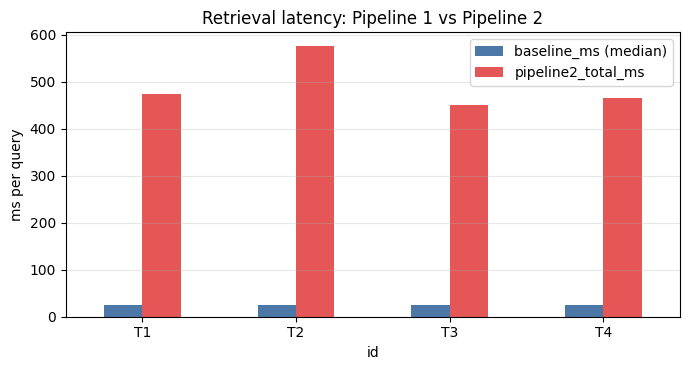

In [17]:
plot_df = lat_df.iloc[:-1].set_index("id")[["baseline_ms (median)", "pipeline2_total_ms"]]
ax = plot_df.plot(kind="bar", figsize=(7, 3.8), rot=0, color=["#4c78a8", "#e45756"])
ax.set_ylabel("ms per query"); ax.set_title("Retrieval latency: Pipeline 1 vs Pipeline 2")
ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

### Scaling experiment
To ground the scaling question in a measurement, time the cross-encoder on **10** candidates and on the **entire corpus**, then extrapolate.

In [18]:
q = next((t["query"] for t in TESTS if "REPLACE" not in t["query"]), "sample question")
def time_ce(n):
    pairs = [(q, chunks[i % len(chunks)].text) for i in range(n)]
    t = time.perf_counter(); ce.predict(pairs, show_progress_bar=False)
    return (time.perf_counter() - t) * 1000

time_ce(10)  # warm-up
ms10   = statistics.median(time_ce(10) for _ in range(3))
msFull = time_ce(len(chunks))
per_pair = msFull / len(chunks)

scal = pd.DataFrame({
    "corpus size": [10, len(chunks), 10_000, 1_000_000],
    "cross-encoder on all (est. s/query)": [ms10/1000, msFull/1000,
                                            per_pair*10_000/1000, per_pair*1_000_000/1000],
})
scal["cross-encoder on all (est. s/query)"] = scal["cross-encoder on all (est. s/query)"].round(2)
print(f"~{per_pair:.1f} ms per (query, chunk) pair on {DEVICE}")
scal

~56.7 ms per (query, chunk) pair on cpu


,corpus size,cross-encoder on all (est. s/query)
0,10,0.89
1,317,17.98
2,10000,567.12
3,1000000,56711.77


## 9. Export results

In [19]:
out = Path("outputs"); out.mkdir(exist_ok=True)
rank_df.to_csv(out / "rank_shifts.csv", index=False)
cand_df.to_csv(out / "candidates.csv", index=False)
lat_df.to_csv(out / "latency.csv", index=False)
scal.to_csv(out / "scaling.csv", index=False)
(out / "answers.json").write_text(json.dumps(answers, indent=2))
(out / "run_info.json").write_text(json.dumps({
    "pdf": PDF_PATH.name, "chunks": len(chunks), "bi_encoder": BI_ENCODER,
    "cross_encoder": CROSS_ENCODER, "llm": f"{LLM_BACKEND}:{LLM_MODEL}",
    "device": DEVICE, "index_seconds": round(INDEX_SECONDS, 2),
    "pdf_sha256": __import__("hashlib").sha256(PDF_PATH.read_bytes()).hexdigest()}, indent=2))
print("saved to", out.resolve())

saved to /kaggle/working/outputs


## Notes for writing your report (in your own words)

The assignment requires a human-written report, so none is drafted here. Use the tables above as evidence and answer:

1. **Architecture:** What does each model see as input, and when are chunk representations computed?
2. **Rank shifts:** Copy the `shift` column. For each rescued query, did Answer 1 hallucinate, omit a clause, or misstate a rule? Quote the differing part of the two answers.
3. **Latency:** Paste `lat_df`. Which stage dominates and by what factor?
4. **Scaling:** Use the scaling table. Think about per-query cost, precomputation and recall vs. precision.

If a query shows *"re-ranker HURT"* or *"gold not in top-10"*, report it honestly. A re-ranker cannot recover a chunk that dense retrieval never returned.